# Scorecard views: who is the best, the typical and the worst client?

A logit sum of trees is a scorecard: each tree splits the clients into segments, each
segment is worth some points, and the score is the sum. `as_tree_sum` reads the ITM,
LightGBM, XGBoost, CatBoost and scikit-learn tree models the same way, so the views below
apply to all of them:

- `segments(X)`: the data marked tree by tree (the rule each row falls in and its points);
- `profiles(X)`: the best, the modal and the worst client;
- `plot_profiles(X)` and `plot_trees(x)`.

Points follow the credit convention: 600 points at odds 1:1, every 20 points halve the
odds of default (`offset`, `pdo`; `scale="logit"` keeps the raw logit).

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, roc_auc_score
from sklearn.model_selection import train_test_split

from credit_data import make_credit_data

X, y = make_credit_data(n=20_000, seed=0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)
print(f"{len(X_train):,} training rows, {len(X_test):,} test rows, "
      f"{y.mean():.1%} defaults, {X['income'].isna().mean():.0%} incomes missing")

14,000 training rows, 6,000 test rows, 10.3% defaults, 5% incomes missing


## Three models with 10 cuts

LightGBM and XGBoost send missing values to the side they learn; bettertrees always
sends them left, so for the two boosters the missing incomes are filled below the
minimum before training (the ITM takes them as they are).

In [2]:
import lightgbm as lgb
import xgboost as xgb

from bettertrees import BudgetClassifier, as_tree_sum

fill = X_train.min() - 1
X_train_f, X_test_f = X_train.fillna(fill), X_test.fillna(fill)
itm = BudgetClassifier(max_splits=10).fit(X_train, y_train)
lgbm = lgb.LGBMClassifier(n_estimators=5, num_leaves=3, learning_rate=0.5,
                          verbose=-1).fit(X_train_f, y_train)          # 5 trees x 2 cuts
xgbm = xgb.XGBClassifier(n_estimators=10, max_depth=1, learning_rate=0.5
                         ).fit(X_train_f, y_train)                      # 10 stumps
sums = {"ITM": (as_tree_sum(itm, X_train), X_test),
        "LightGBM": (as_tree_sum(lgbm, X_train_f), X_test_f),
        "XGBoost": (as_tree_sum(xgbm, X_train_f), X_test_f)}
pd.DataFrame({name: {"trees": len(s.trees_), "cuts": s.n_splits_,
                     "test AUC": roc_auc_score(y_test, s.predict_proba(Xt)[:, 1])}
              for name, (s, Xt) in sums.items()}).T.round(4)

,trees,cuts,test AUC
ITM,6.0,10.0,0.6881
LightGBM,5.0,10.0,0.6853
XGBoost,10.0,10.0,0.6856


## The data marked tree by tree

One column per tree with the rule of the leaf, one with its points; `base` plus the
points is the score, exactly.

In [3]:
seg = itm.segments(X_test)
seg.iloc[:3].T

,15877,6915,6457
base,662.493915,662.493915,662.493915
tree_1,late_payments > 0.5 and debt_ratio <= 0.4325,late_payments > 0.5 and debt_ratio <= 0.4325,late_payments <= 0.5
tree_1_points,-8.8093,-8.8093,9.816441
tree_2,late_payments <= 1.5,late_payments > 1.5,late_payments <= 1.5
tree_2_points,2.751424,-20.244394,2.751424
tree_3,"(income <= 36,350 or missing) and credit_lines...","(income <= 36,350 or missing) and credit_lines...","income > 36,350"
tree_3_points,-0.788694,-0.788694,7.342881
tree_4,months_employed <= 12.5,months_employed > 12.5,months_employed <= 12.5
tree_4_points,-8.984216,3.097226,-8.984216
tree_5,"(income <= 50,850 or missing) and debt_ratio <...","(income <= 50,850 or missing) and debt_ratio <...","(income <= 50,850 or missing) and debt_ratio <..."


Each tree is a segmentation, so it can be checked against the observed default rate:

In [4]:
(seg.assign(default=y_test)
    .groupby(["tree_1", "tree_1_points"])["default"].agg(["size", "mean"])
    .round(3))

,,size,mean
tree_1,tree_1_points,,
late_payments <= 0.5,9.816441,4029,0.072
late_payments > 0.5 and debt_ratio <= 0.4325,-8.809300,1591,0.148
late_payments > 0.5 and debt_ratio > 0.4325,-32.073581,380,0.245


## Best, modal and worst client

`kind="observed"` (the default) takes real rows: the best and the worst score in the data.
The modal client is the most frequent combination of leaves.

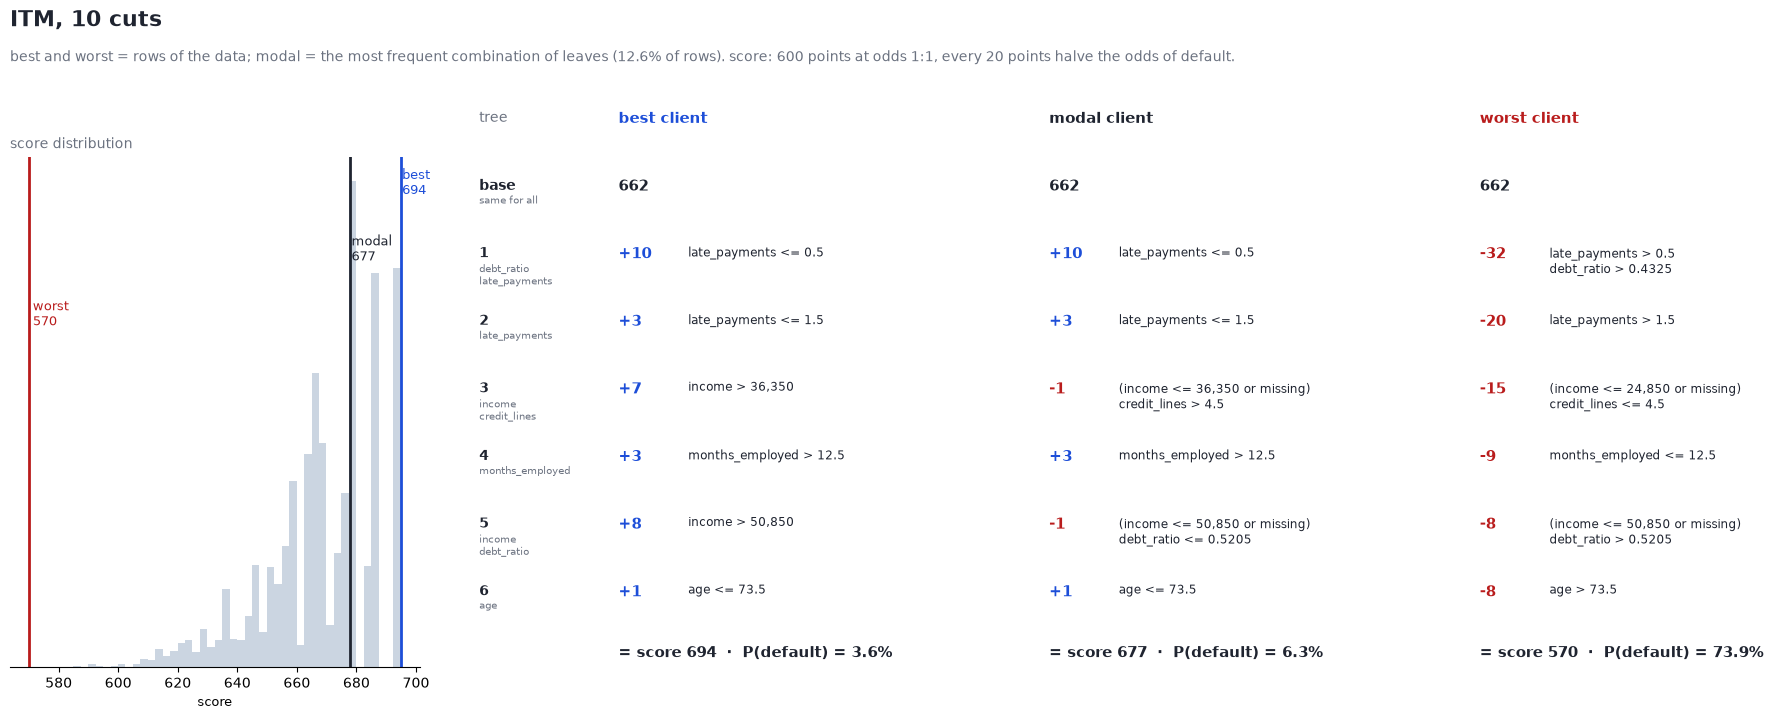

In [5]:
fig = itm.plot_profiles(X_test, bad_label="default", title="ITM, 10 cuts")

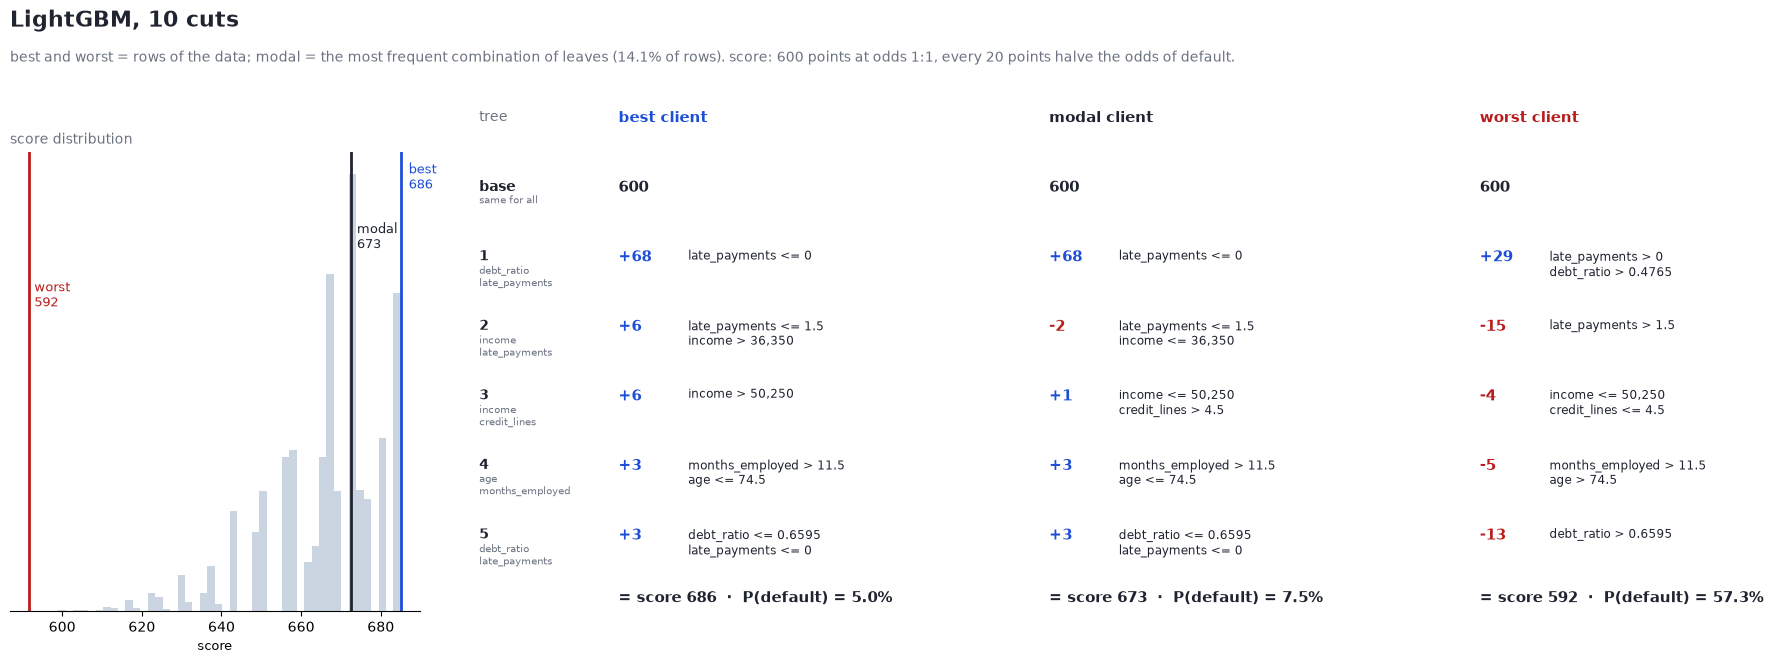

In [6]:
s, Xt = sums["LightGBM"]
fig = s.plot_profiles(Xt, bad_label="default", title="LightGBM, 10 cuts")

`kind="feasible"` searches the combinations of leaves that the cuts allow. The extreme
combination can be more extreme than any client in the data:

In [7]:
pd.concat({"observed": itm.profiles(X_test)[["score", "p"]],
           "feasible": itm.profiles(X_test, kind="feasible")[["score", "p"]]}, axis=1).round(3)

observed        feasible       
           score      p    score      p
profile                                
best     694.928  0.036  694.928  0.036
modal    677.698  0.063  677.698  0.063
worst    569.910  0.739  569.910  0.739

## Grown in parallel, not in sequence

Boosting finishes one tree before starting the next. The ITM chooses, at every cut,
any leaf of any tree or a new tree. `plot_growth` draws the order of the cuts: a
staircase for the booster, jumps between trees for the ITM (hollow marker = a new tree).

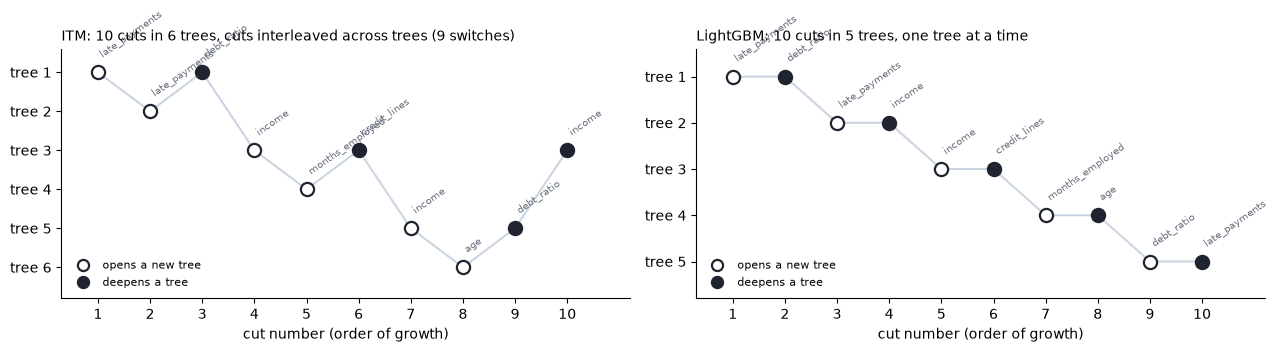

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
itm.plot_growth(ax=axes[0])
sums["LightGBM"][0].plot_growth(ax=axes[1])
fig.tight_layout()

## The trees, with the path of the worst client

The orange numbers give each cut's place in the order of growth.

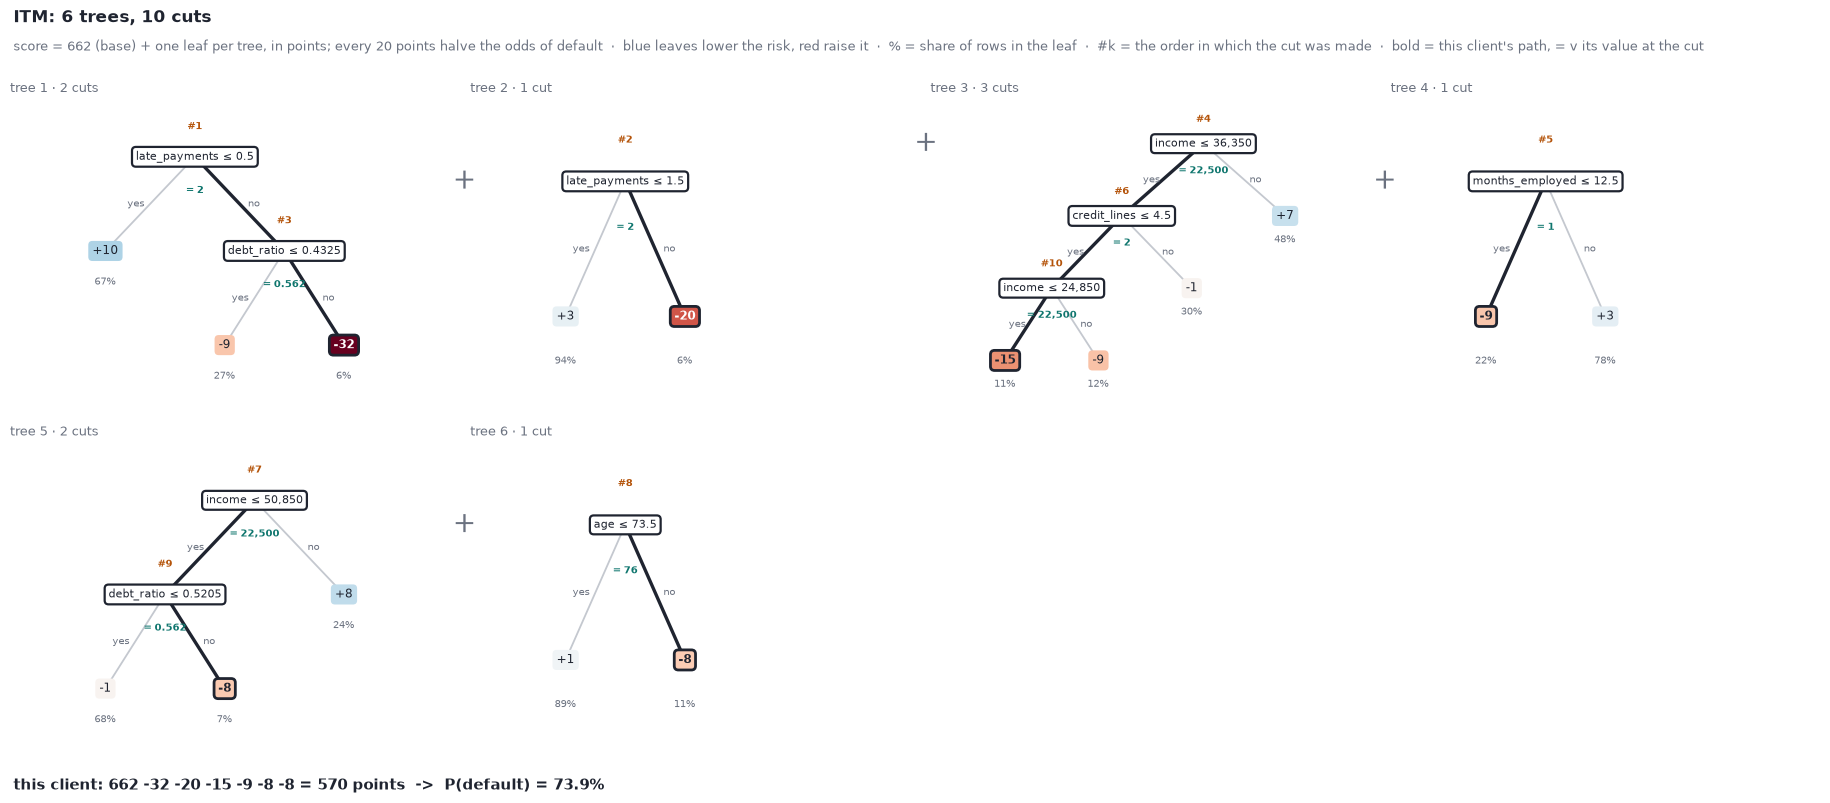

In [9]:
worst = itm.profiles(X_test).loc["worst", "row"]
fig = itm.plot_trees(X_test.loc[[worst]], X=X_test, bad_label="default")